# Choosing a background

Every score a motif gives a sequence is a log-odds ratio, the log of the
motif's probability of a letter at a position over the background probability
of that same letter. Because the background sits in the denominator of every
position of every motif, choosing it poorly quietly changes every score, and
the P-values from [`motif_pvalue()`][universalmotif.motif_pvalue] and the
q-values from [`enrich_motifs()`][universalmotif.enrich_motifs] inherit the
problem along with them. It is surprisingly easy to end up reporting a motif
as highly enriched when really it is just more common in the targets than in
whichever background happened to be chosen.

This guide makes that concrete with a small controlled experiment, in which
the motif and the target sequences are held fixed while only the background
is changed. We first look at single-hit P-values under different letter
frequencies, then at shuffled backgrounds of different k-let orders and at
composition-matched backgrounds, and see how each of them changes the outcome
of an enrichment test. Finally we repeat the exercise on real ChIP-seq peaks
and close with a short guide to choosing a background. The
[sequences](sequences.ipynb) guide covers the functions for making
backgrounds in more detail, and the
[comparison and P-values](comparison-and-pvalues.ipynb) guide explains how
P-values are calculated.

Unlike most of the guides, the last part of this one uses real data, which
is downloaded the first time it is run. Let us start with the imports:

In [1]:
import pathlib
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## A controlled experiment

Let us build a set of target sequences for which we know the answer. We start
with 500 random sequences of 500 bp, AT-rich like many plant promoters. Real
sequences also have preferences for some pairs of letters over others, so
rather than drawing every letter independently we give
[`create_sequences()`][universalmotif.create_sequences] the frequencies of
all sixteen dinucleotides, from which it draws sequences with a first-order
Markov model. Here the dinucleotide TA is made rarer than its letters alone
would predict, which is a common feature of plant genomes:

In [2]:
p = {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3}
dinucs = {x + y: p[x] * p[y] for x in "ACGT" for y in "ACGT"}
dinucs["TA"] *= 0.6
total = sum(dinucs.values())
dinucs = {k: v / total for k, v in dinucs.items()}
host = um.create_sequences(seqnum=500, seqlen=500, freqs=dinucs, seed=2026)

Now for the motif. We use a stretched E-box, `CACGTGCA`, with 80% of each
position given to the consensus letter, so that the sites sampled from it
vary somewhat as real binding sites do:

In [3]:
consensus = um.create_motif("CACGTGCA").matrix
myc = um.create_motif(
    np.where(consensus == 1, 0.8, 0.2 / 3),
    alphabet="DNA", name="MYC_like", nsites=100, pseudocount=1,
)
myc

       Motif name:   MYC_like
         Alphabet:   DNA
             Type:   PPM
          Strands:   +-
         Total IC:   7.26
      Pseudocount:   1
        Consensus:   CACGTGCA
     Target sites:   100

     C    A    C    G    T    G    C    A
A 0.07 0.80 0.07 0.07 0.07 0.07 0.07 0.80
C 0.80 0.07 0.80 0.07 0.07 0.07 0.80 0.07
G 0.07 0.07 0.07 0.80 0.07 0.80 0.07 0.07
T 0.07 0.07 0.07 0.07 0.80 0.07 0.07 0.07

[`implant_motifs()`][universalmotif.implant_motifs] then samples one site
from the motif for every sequence and writes it in at a random position and
on a random strand. Its table of planted sites is our answer key, and every
analysis that follows uses these same 500 target sequences:

In [4]:
target, planted = um.implant_motifs(myc, host, n_per_seq=1, seed=2026, return_indices=True)
planted.head(3)

sequence_i,motif_i,start,width,strand,planted
i64,i64,i64,i64,str,str
0,0,213,8,"""-""","""TGCCCGTG"""
1,0,295,8,"""+""","""CATGTGGA"""
2,0,185,8,"""+""","""CACGCTCA"""


Let us check the composition of the targets with
[`get_bkg()`][universalmotif.get_bkg], along with the ratio of the observed
TA frequency to the one expected from the frequencies of T and A. We will
reuse this small helper again later:

In [5]:
def obs_exp(sequences, klet):
    freqs = um.get_bkg(sequences, k=[1, 2])
    f = dict(zip(freqs["klet"], freqs["probability"]))
    return f[klet] / (f[klet[0]] * f[klet[1]])

print(um.get_bkg(target, k=1))
print(round(obs_exp(target, "TA"), 2))

shape: (4, 3)
┌──────┬───────┬─────────────┐
│ klet ┆ count ┆ probability │
│ ---  ┆ ---   ┆ ---         │
│ str  ┆ i64   ┆ f64         │
╞══════╪═══════╪═════════════╡
│ A    ┆ 67282 ┆ 0.269128    │
│ C    ┆ 52853 ┆ 0.211412    │
│ G    ┆ 52404 ┆ 0.209616    │
│ T    ┆ 77461 ┆ 0.309844    │
└──────┴───────┴─────────────┘
0.75


The targets are about 58% A and T, and TA turns up at three quarters of the
rate expected from their letters. (Lowering TA also pulls the frequency of A
down a little, since every A that would have followed a T is now less likely.)

## Single-hit P-values

Perhaps the simplest way to see the effect of the background is to take a
single score and ask how likely it is that a random site, drawn from some
background, scores at least as high. This is what
[`motif_pvalue()`][universalmotif.motif_pvalue] answers, and its `bkg_probs`
argument sets the background. Let us scan the targets and take the median
score of the hits as a typical, moderately good match:

In [6]:
hits = um.scan_sequences(myc, target, pvalue=1e-3, nthreads=2)
score = hits["score"].median()
print(hits.height, score)

443 9.75


Now we can ask for the P-value of that one score under three different
backgrounds. Since the score of a match depends on the background too, the
table also shows the highest score the motif can reach under each of them,
which we get from [`motif_score()`][universalmotif.motif_score] after giving
the motif each background in turn:

In [7]:
bkgs = {
    "uniform": {"A": 0.25, "C": 0.25, "G": 0.25, "T": 0.25},
    "AT-rich": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3},
    "GC-rich": {"A": 0.2, "C": 0.3, "G": 0.3, "T": 0.2},
}
pl.DataFrame({
    "background": list(bkgs),
    "max_score": [um.motif_score(myc.replace(bkg=b), 1.0) for b in bkgs.values()],
    "pvalue": [um.motif_pvalue(myc, score=score, bkg_probs=b) for b in bkgs.values()],
})

background,max_score,pvalue
str,f64,f64
"""uniform""",13.2,0.000381
"""AT-rich""",14.021,0.000242
"""GC-rich""",12.851,0.000149


The same score of 9.75 gets three different P-values, from about 3.8e-4
under the uniform background down to 1.5e-4 under the GC-rich one. Note that
changing the background does more than change how often random sites score
highly, since it also rebuilds the log-odds matrix itself, and so the very
same number sits at a different place on each scale (the maximum possible
score moves from 12.85 to 14.02). A difference of a factor of two or three
is the small end of the effect, however. Once we move from single hits to
enrichment tests over whole sets of sequences, the background can decide
whether a motif is called enriched at all.

## Shuffled backgrounds

When there is no obvious set of background sequences to hand, a common
choice is to shuffle the targets themselves.
[`shuffle_sequences()`][universalmotif.shuffle_sequences] keeps the
frequencies of every k-let of a chosen size `k`, so with `k=1` only the
letter frequencies survive, with `k=2` the dinucleotide frequencies too, and
so on. Let us shuffle the targets at three orders and compare a few of the
dinucleotide and trinucleotide frequencies:

In [8]:
shuffled = {k: um.shuffle_sequences(target, k=k, seed=2026) for k in (1, 2, 3)}
klets = ["AT", "CG", "TA", "ATA", "TAT"]

def klet_freqs(sequences, label):
    freqs = um.get_bkg(sequences, k=[2, 3]).filter(pl.col("klet").is_in(klets))
    return freqs.select("klet", pl.col("probability").round(4).alias(label))

table = klet_freqs(target, "target")
for k, seqs in shuffled.items():
    table = table.join(klet_freqs(seqs, f"k={k}"), on="klet")
table

klet,target,k=1,k=2,k=3
str,f64,f64,f64,f64
"""AT""",0.081,0.0836,0.081,0.081
"""CG""",0.0434,0.0445,0.0434,0.0434
"""TA""",0.0629,0.0836,0.0629,0.0629
"""ATA""",0.0164,0.0225,0.016,0.0164
"""TAT""",0.0191,0.0261,0.019,0.0191


The `k=1` shuffle has lost the shortage of TA, which rises from 0.0629 to
0.0836, and the trinucleotides containing it rise along with it. The `k=2`
and `k=3` shuffles keep the dinucleotides exactly, and the `k=3` shuffle the
trinucleotides as well. How much does this matter for an enrichment test?
Let us add four distractor motifs that were never planted in the targets and
test all five against each shuffled background with
[`enrich_motifs()`][universalmotif.enrich_motifs], which shuffles the targets
itself when given `shuffle_k`:

In [9]:
distractors = [
    um.create_motif(c, name=n, nsites=100, pseudocount=1)
    for c, n in [("AAAAAAAA", "polyA"), ("TATATATA", "TATA"), ("CGCGCGCG", "polyCG"), ("GAGAGAGA", "GArep")]
]
motifs = [myc, *distractors]

def run_enrich(label, **kwargs):
    res = um.enrich_motifs(motifs, target, pvalue=1e-3, qvalue=1, nthreads=2, **kwargs)
    return res.select(
        pl.lit(label).alias("background"), "motif", "target_seq_hits", "bkg_seq_hits",
        pl.col("enrichment").round(2), "qvalue",
    )

shuffle_results = pl.concat([run_enrich(f"shuffle k={k}", shuffle_k=k, seed=2026) for k in (1, 2, 3)])
shuffle_results.sort("motif", "background")

background,motif,target_seq_hits,bkg_seq_hits,enrichment,qvalue
str,str,i64,i64,f64,f64
"""shuffle k=1""","""GArep""",170,127,1.34,0.003092
"""shuffle k=2""","""GArep""",170,140,1.21,0.059857
"""shuffle k=3""","""GArep""",170,158,1.08,0.28744
"""shuffle k=1""","""MYC_like""",307,115,2.67,8.3429e-35
"""shuffle k=2""","""MYC_like""",307,127,2.42,2.1876e-30
"""shuffle k=3""","""MYC_like""",307,157,1.96,5.1602e-21
"""shuffle k=1""","""TATA""",92,168,0.55,1.0
"""shuffle k=2""","""TATA""",92,76,1.21,0.172302
"""shuffle k=3""","""TATA""",92,69,1.33,0.07437


The planted `MYC_like` motif is strongly enriched at every order, but the
distractors are where the shuffles part ways. With `k=1`, `TATA` looks
depleted in the targets, with 92 sequences carrying a hit against 168 in the
background, simply because the shuffle put back all the TA steps the targets
were missing. At the same time `polyA` and `GArep` come out as significantly
enriched (q-values of 5e-5 and 0.003) even though neither was planted. This
is the other side of the same coin, since the missing TA steps are made up
for by slightly more AA and GA steps than the letters alone predict, and a
letter-only shuffle loses those too. With `k=2` and `k=3` none of the distractors
reaches a q-value of 0.05.

Note that higher orders are not free, however. The enrichment of `MYC_like`
falls from 2.67 with `k=1` to 1.96 with `k=3`, because a shuffle that keeps
every trinucleotide also keeps the trinucleotides of the planted sites, and
so it rebuilds fragments of the motif in the background. A dinucleotide
shuffle is usually a sensible compromise for transcription factor motifs.

## Composition-matched backgrounds

Shuffling only ever rearranges the targets, so a better background, when one
is available, is a set of real sequences from elsewhere that resemble the
targets in composition. [`match_bkg()`][universalmotif.match_bkg] draws such
a set from a larger universe of candidates, matching every target with a
candidate of similar GC content and length. In real analyses the universe is
usually random windows from the genome, which we will use in the next
section. Here we stand in for the genome with 5000 sequences drawn from the
same dinucleotide model as the targets. For comparison we also make a pool of
uniform random sequences, which is what a background chosen without any
thought for composition amounts to:

In [10]:
uniform_pool = um.create_sequences(seqnum=500, seqlen=500, seed=2026)
universe = um.create_sequences(seqnum=5000, seqlen=500, freqs=dinucs, seed=1)
matched = um.match_bkg(target, universe=universe, seed=2026)
len(matched)

500

Now let us run the same five motifs against both backgrounds, and put them
next to the dinucleotide shuffle:

In [11]:
results = pl.concat([
    shuffle_results,
    run_enrich("uniform", bkg_sequences=uniform_pool),
    run_enrich("matched", bkg_sequences=matched),
])
results.filter(pl.col("background").is_in(["shuffle k=2", "uniform", "matched"])).sort("motif", "background")

background,motif,target_seq_hits,bkg_seq_hits,enrichment,qvalue
str,str,i64,i64,f64,f64
"""matched""","""GArep""",170,141,1.21,0.070423
"""shuffle k=2""","""GArep""",170,140,1.21,0.059857
"""uniform""","""GArep""",170,130,1.31,0.006021
"""matched""","""MYC_like""",307,106,2.9,2.0855e-38
"""shuffle k=2""","""MYC_like""",307,127,2.42,2.1876e-30
"""uniform""","""MYC_like""",307,126,2.44,4.8588e-31
"""matched""","""TATA""",92,75,1.23,0.147523
"""shuffle k=2""","""TATA""",92,76,1.21,0.172302
"""uniform""","""TATA""",92,79,1.16,0.197467


A few things in this table are worth dwelling on. The planted `MYC_like`
motif is enriched under every background, and it is the matched background
that gives it both the highest enrichment, 2.9, and the smallest q-value. Against the
uniform pool, `polyA` looks even more significant than the motif we
actually planted, with a q-value of 1e-37, for the simple reason that the
targets are AT-rich and the uniform pool is not. Against the matched
background, or the dinucleotide shuffle, `polyA` sits at an enrichment of
about 1 and is correctly called not enriched. `polyCG` swings the other way,
looking depleted against the uniform pool (23 sequences with hits against
80) and unremarkable against the composition-aware backgrounds. Someone
looking only at the uniform results might conclude that no GC-rich motif is
enriched, which happens to be true here, but only because the difference in
composition is doing all of the work.

Pivoting the q-values puts all five backgrounds side by side:

In [12]:
results.pivot(on="background", index="motif", values="qvalue")

motif,shuffle k=1,shuffle k=2,shuffle k=3,uniform,matched
str,f64,f64,f64,f64,f64
"""MYC_like""",8.3429e-35,2.1876e-30,5.1602e-21,4.8588e-31,2.0855e-38
"""polyA""",0.00005,0.440111,0.952445,1.0162e-37,0.875348
"""GArep""",0.003092,0.059857,0.28744,0.006021,0.070423
"""polyCG""",0.625,0.440111,0.077218,1.0,0.698379
"""TATA""",1.0,0.172302,0.07437,0.197467,0.147523


If there is a single thing to take away from this guide, it is more or less
the `polyA` row: the same motif, on the same sequences, can be reported with
a q-value of 1e-37 or of 0.88 depending on nothing more than the choice of
background.

## Real ChIP-seq peaks

The same pattern turns up on real data. Let us use the peaks of the
*Arabidopsis thaliana* B3-domain repressor VAL1 from Yuan et al. (2021), and
the TAIR10 genome sequence from Ensembl Plants. The
[ChIP-seq workflow](chipseq-workflow.ipynb) guide analyses these peaks from
start to finish, so here we only need their sequences. This small helper
downloads each file once into a cache directory in your home folder and
reuses it afterwards (the genome is about 36 MB):

In [13]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / url.rsplit("/", 1)[-1]
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

bed_path = fetch("https://raw.githubusercontent.com/bjmt/universalmotif/master/inst/extdata/VAL1-GFP_val1_calledPeaks.bed")
genome_path = fetch("https://ftp.ensemblgenomes.ebi.ac.uk/pub/plants/current/fasta/arabidopsis_thaliana/dna/Arabidopsis_thaliana.TAIR10.dna.toplevel.fa.gz")

[`read_fasta()`][universalmotif.read_fasta] reads the gzipped genome
directly. Its headers carry a description after the chromosome name, so we
keep only the first word. The peaks are in a BED file, which is a plain
tab-separated table with 0-based starts. We centre a 500 bp window on every
peak, converting to the 1-based coordinates used throughout the package, and
cut the windows out of the chromosomes:

In [14]:
genome = {name.split()[0]: seq for name, seq in um.read_fasta(genome_path).items()}
peaks = pl.read_csv(
    bed_path, separator="\t", has_header=False,
    new_columns=["chrom", "start", "end", "name", "score", "strand"],
    schema_overrides={"chrom": pl.String},
)
mid = (peaks["start"] + 1 + peaks["end"]) // 2
windows = pl.DataFrame({"chrom": peaks["chrom"], "start": mid - 249, "end": mid + 250})
lengths = {chrom: len(seq) for chrom, seq in genome.items()}
windows = windows.filter(pl.col("start") >= 1, pl.col("end") <= pl.col("chrom").replace_strict(lengths))
peak_seqs = {f"{c}:{s}-{e}": genome[c][s - 1:e] for c, s, e in windows.iter_rows()}
len(peak_seqs)

5318

All 5318 peaks fit on their chromosomes. Let us look at their composition,
and at the TA ratio before and after a letter-only shuffle:

In [15]:
print(um.get_bkg(peak_seqs, k=1))
shuffled_peaks = um.shuffle_sequences(peak_seqs, k=1, seed=2026)
print(round(obs_exp(peak_seqs, "TA"), 2), round(obs_exp(shuffled_peaks, "TA"), 2))

shape: (4, 3)
┌──────┬────────┬─────────────┐
│ klet ┆ count  ┆ probability │
│ ---  ┆ ---    ┆ ---         │
│ str  ┆ i64    ┆ f64         │
╞══════╪════════╪═════════════╡
│ A    ┆ 851294 ┆ 0.320156    │
│ C    ┆ 478870 ┆ 0.180094    │
│ G    ┆ 477963 ┆ 0.179753    │
│ T    ┆ 850873 ┆ 0.319997    │
└──────┴────────┴─────────────┘
0.77 1.0


The peaks are 64% A and T, and TA is found at 0.77 of its expected rate, a
shortage that the `k=1` shuffle erases completely. Our synthetic targets
were not so far from the real thing after all.

For the matched background, [`match_bkg()`][universalmotif.match_bkg] can
draw random windows from the genome itself. We give it the genome, the peak
windows to avoid, and the five nuclear chromosomes, and it samples candidate
windows of the same width as the peaks before matching them on GC content.
[`plot_match_bkg()`][universalmotif.plot_match_bkg] confirms that the two
sets have practically the same GC distribution. We also make a uniform pool
of the same size, as before:

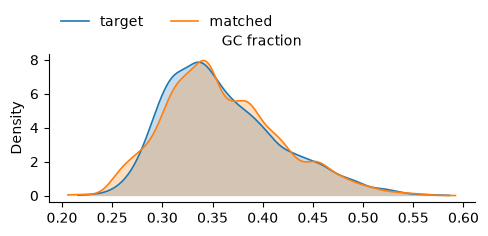

In [16]:
genome_bkg = um.match_bkg(
    peak_seqs, genome=genome, exclude=windows,
    chromosomes=["1", "2", "3", "4", "5"], seed=2026,
)
uniform_peaks = um.create_sequences(seqnum=len(peak_seqs), seqlen=500, seed=2026)
fig = um.plot_match_bkg(peak_seqs, genome_bkg, by=["gc"], figsize=(5, 2.5))

Now let us run the same sweep with three motifs: the RY element `CATGCA`,
which VAL1 binds, and two AT-rich distractors:

In [17]:
val1_motifs = [
    um.create_motif(c, name=n, nsites=100, pseudocount=1)
    for c, n in [("CATGCA", "RY"), ("AAAAAAAA", "polyA"), ("TATATATA", "TATA")]
]

def run_val1(label, **kwargs):
    res = um.enrich_motifs(val1_motifs, peak_seqs, pvalue=1e-3, qvalue=1, nthreads=2, **kwargs)
    return res.select(
        pl.lit(label).alias("background"), "motif", "target_seq_hits", "bkg_seq_hits",
        pl.col("enrichment").round(2), "qvalue",
    )

pl.concat([
    run_val1("shuffle k=1", shuffle_k=1, seed=2026),
    run_val1("shuffle k=2", shuffle_k=2, seed=2026),
    run_val1("uniform", bkg_sequences=uniform_peaks),
    run_val1("matched", bkg_sequences=genome_bkg),
]).sort("motif", "background")

background,motif,target_seq_hits,bkg_seq_hits,enrichment,qvalue
str,str,i64,i64,f64,f64
"""matched""","""RY""",3222,950,3.39,0.0
"""shuffle k=1""","""RY""",3222,819,3.93,0.0
"""shuffle k=2""","""RY""",3222,950,3.39,0.0
"""uniform""","""RY""",3222,1077,2.99,0.0
"""matched""","""TATA""",2837,2415,1.17,1.5719e-16
"""shuffle k=1""","""TATA""",2837,2824,1.0,0.407821
"""shuffle k=2""","""TATA""",2837,1676,1.69,9.4876e-116
"""uniform""","""TATA""",2837,786,3.61,0.0
"""matched""","""polyA""",4643,4277,1.09,3.7846e-22


The RY element is enriched about three- to four-fold under every background,
with q-values so small that they are reported as zero. The distractors tell
the more interesting story. Against the uniform pool, `polyA` and `TATA`
come out at more than three-fold enrichment, which is entirely down to the
AT-richness of the peaks. The `TATA` row also shows why a dinucleotide
shuffle is not a complete answer on real sequences. TA repeats are a feature
of the genome that reaches well beyond pairs of letters, and a `k=2` shuffle
breaks them up, so `TATA` comes out 1.69-fold enriched against it. The `k=1`
shuffle puts it at 1.0, but likely only because putting back the missing TA
steps happens to cancel out the loss of the repeats, and the same shuffle
still finds `polyA` 1.29-fold enriched. Against the matched genomic windows, both
distractors fall to 1.09- to 1.17-fold, which is about as close to "not
enriched" as real data gets.

Note that with more than 5000 sequences in each set, even these small
differences come with very small q-values (1.6e-16 for `TATA` against the
matched background). With this many sequences an enrichment test can detect
real but tiny differences in composition between peaks and the rest of the
genome, and so the size of the enrichment deserves as much attention as its
q-value.

## A decision guide

There is likely never one background that works in every situation, but the
following is a reasonable place to start:

| Situation | Background |
|---|---|
| A quick check of a short motif in sequences of balanced composition | the uniform default |
| Short sequences from one organism, with no genome to hand | [`shuffle_sequences()`][universalmotif.shuffle_sequences] with `k=2`, or `shuffle_k=2` in [`enrich_motifs()`][universalmotif.enrich_motifs] |
| Sequences with a strong composition bias, such as plant promoters or CpG islands | [`match_bkg()`][universalmotif.match_bkg] against random genomic windows |
| Motifs whose scores depend on dinucleotides, such as CpG-containing motifs | a `k=2` or `k=3` shuffle, or better [`match_bkg()`][universalmotif.match_bkg] |
| P-values and score thresholds for a particular set of sequences | `bkg_probs` set to their letter frequencies from [`get_bkg()`][universalmotif.get_bkg] |

When in doubt, my suggestion would be to simply run the sweep.
Running [`enrich_motifs()`][universalmotif.enrich_motifs] against two or
three backgrounds takes seconds, and it tells you straight away whether a
significant result survives a change of background. If a motif drops from a
q-value of 1e-20 to above 0.05 just by going from `shuffle_k=1` to
`shuffle_k=2`, then it was being driven by composition all along, which is a
fairly common failure but happily an easy one to correct.

The [scanning and enrichment](scanning-and-enrichment.ipynb) guide covers
enrichment tests more generally, and the
[large genomes](large-genomes.ipynb) guide shows how to work with whole
genomes without holding them in memory as strings. The
[API reference](../reference/index.md) has the details of every function used
here.